# **DS111 - Introduction to data science - 2025**

**Members**

 446008121 سديم المنصور
 
 وسن المعاوي 446008044
 
 صبا بن يحيى 446008094 
 
 دانه الحيدر 446008060
 
 لطيفه الرشيد 446008070

Class: 22S

__________________________________________________________________________________________

# **--------------------Diabetes prediction project--------------------**

**Project description**

This project aims to analyze and predict diabetes occurrence using this dataset. By leveraging data preprocessing, statistical analysis, and machine learning techniques, the project seeks to identify the key factors associated with diabetes and develop predictive models that can assist in early diagnosis.

**Dataset description**

The dataset is from Kaggle and originates from the National Institute of Diabetes and Digestive and Kidney Diseases. It consists of medical diagnostic measurements collected from Pima Indian women aged 21 years or older. These measurements include age, diabetes pedigree function, body mass index (BMI), insulin, skin thickness, blood pressure, glucose, and pregnancies.

_____________

**The goals**

1- handle missing or noisy data.

2- create appropriate data visualization.

3- Analyze the relationship between medical variables and diabetes diagnosis.

4- Determine the most significant predictors of diabetes.

5- Apply machine learning models to predict diabetes occurrence.

__________________________________________________________________________________________

# **Dataset loading**

In [1]:
# import all related libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Load dataset
df = pd.read_csv('diabetesP(A).csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...,...
761,10,101.0,76,48,180,32.9,0.171,63.0,0
762,2,122.0,70,27,0,36.8,0.340,27.0,0
763,5,121.0,72,23,112,26.2,0.245,30.0,0
764,1,126.0,60,0,0,30.1,0.349,47.0,1


# **Basic summary statistics**

In [3]:
# print statistic summary for a data
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,766.000000,765.000000,766.000000,766.000000,766.000000,766.000000,766.000000,765.000000,766.000000
mean,3.845953,121.003922,69.100522,20.535248,80.007833,31.992820,0.472189,33.254902,0.348564
std,3.373062,31.968223,19.380243,15.936908,115.322203,7.887884,0.331615,11.780458,0.476827
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.244000,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,34.000000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,32.000000,127.750000,36.575000,0.626750,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [4]:
# printing the columns and rows 
df.shape

(766, 9)

###### 766 is the rows number , 9 is the columns number

# **Lets Start The Data Preprocessing !**

# Missing data

In [5]:
#check each individual cell in the dataset to determine if it contains a null value or not
df.isnull()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
761,False,False,False,False,False,False,False,False,False
762,False,False,False,False,False,False,False,False,False
763,False,False,False,False,False,False,False,False,False
764,False,False,False,False,False,False,False,False,False


In [6]:
# Check if any column in the DataFrame contains null values.  
print(df.isnull().any())

Pregnancies                 False
Glucose                      True
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                          True
Outcome                     False
dtype: bool


In [7]:
# Count the number of null values in each column of the DataFrame.  
print(df.isnull().sum())

Pregnancies                 0
Glucose                     1
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         1
Outcome                     0
dtype: int64


We have null values one for each column (Glucose ,Age )

# 1-Remove Rows with Null Values

In [8]:
df.shape

(766, 9)

In [9]:
# Create a new DataFrame by removing only the rows where all values are null.
new_df = df.dropna()  
new_df  

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...,...
761,10,101.0,76,48,180,32.9,0.171,63.0,0
762,2,122.0,70,27,0,36.8,0.340,27.0,0
763,5,121.0,72,23,112,26.2,0.245,30.0,0
764,1,126.0,60,0,0,30.1,0.349,47.0,1


In [10]:
# Check and display the count of missing values in each column of `new_df`.
print(new_df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [11]:
new_df.shape

(764, 9)

 # 2-Replace Only For Specified Columns


In [12]:
df1=df.copy()

In [13]:
#Replace missing values in the "Glucose" column with 160
df1["Glucose"].fillna(160, inplace = True)

In [14]:
#Replace missing values in the "Age" column with 40
df1["Age"].fillna(40, inplace = True)

In [15]:
# Check and display the count of missing values in each column of `df1`.
print(df1.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


# 3.Replace Empty Values by using Mean or Median, or Mode

In [16]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     1
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         1
Outcome                     0
dtype: int64


**1- Replacing missing values with the median.**

In [17]:
#Median
dfmedian =df.copy()
x = dfmedian["Age"].median()
dfmedian["Age"].fillna(x, inplace = True)

y = dfmedian["Glucose"].median()
dfmedian["Glucose"].fillna(x, inplace = True)

dfmedian

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...,...
761,10,101.0,76,48,180,32.9,0.171,63.0,0
762,2,122.0,70,27,0,36.8,0.340,27.0,0
763,5,121.0,72,23,112,26.2,0.245,30.0,0
764,1,126.0,60,0,0,30.1,0.349,47.0,1


In [18]:
# Check and display the count of missing values in each column of `dfmedian`.
print(dfmedian.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**2- Replacing missing values with the Mean.**

In [19]:
#Mean
dfmean = df.copy()
x = dfmean["Age"].mean()
dfmean["Age"].fillna(x, inplace = True)

y = dfmean["Glucose"].mean()
dfmean["Glucose"].fillna(x, inplace = True)

dfmean

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...,...
761,10,101.0,76,48,180,32.9,0.171,63.0,0
762,2,122.0,70,27,0,36.8,0.340,27.0,0
763,5,121.0,72,23,112,26.2,0.245,30.0,0
764,1,126.0,60,0,0,30.1,0.349,47.0,1


In [20]:
# Check and display the count of missing values in each column of `dfmean`.
print(dfmean.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**3- Replacing missing values with the Mode.**

In [21]:
#Mode
dfmode = df.copy()
x = dfmode["Age"].mode()[0]
dfmode["Age"].fillna(x, inplace = True)


y = dfmode["Glucose"].mode()[0]
dfmode["Glucose"].fillna(x, inplace = True)
dfmode


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1
...,...,...,...,...,...,...,...,...,...
761,10,101.0,76,48,180,32.9,0.171,63.0,0
762,2,122.0,70,27,0,36.8,0.340,27.0,0
763,5,121.0,72,23,112,26.2,0.245,30.0,0
764,1,126.0,60,0,0,30.1,0.349,47.0,1


In [22]:
# Check and display the count of missing values in each column of `dfmode`.
print(dfmode.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


**We Chose median to fill missing values in 'Age' and 'Glucose' because both columns are numerical and contain outliers.** 

**[ Median is a good choice for such data as it is less affected by outliers. ]**


# 4. Removing Duplicates 


In [23]:
#Now we are checking for Duplicates Rows
print(dfmedian.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
761    False
762    False
763    False
764    False
765    False
Length: 766, dtype: bool


 Ther is no Duplicates data

# **Exploratory Data Analysis (EDA)**

**--1D--**

**Histogram**

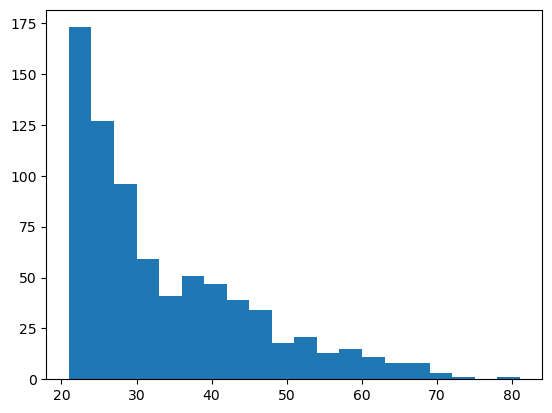

In [24]:
# plot histogram for variable ( Age ) in a dataframe using 20 bins 
plt.hist(dfmedian['Age'], bins = 20)
plt.show()

This histogram shows the distribution of Age in the dataset. Most values are concentrated around younger ages, with fewer older individuals. This suggests that the dataset is skewed towards a younger population.

**Boxplot**

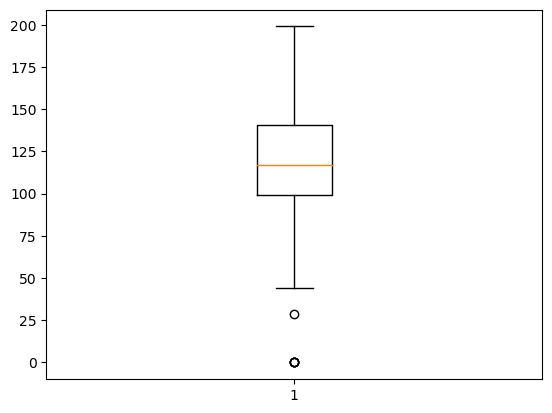

In [25]:
# Boxplot for a variable (Glucose)
plt.boxplot(dfmedian['Glucose'])
plt.show()

The boxplot displays the distribution of Glucose levels. The median is centered, and there is one outlier at the lower end. This suggests that while most values are within a normal range, there is at least one unusually low glucose value.

**Cat plot**

/opt/conda/envs/anaconda-panel-2023.05-py310/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


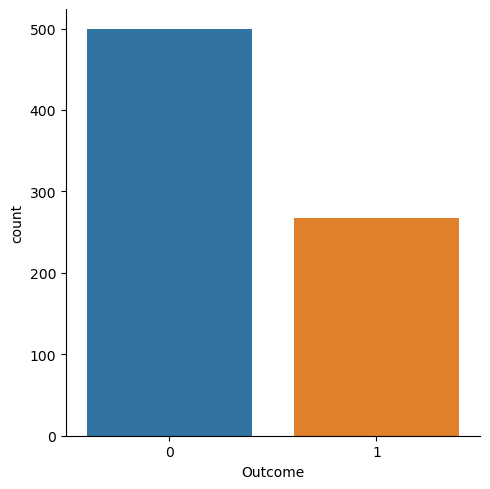

In [26]:
# Plotting a count plot for a categorical column using catplot
sns.catplot(x="Outcome", kind="count", data=dfmedian)
plt.show()

This count plot shows the number of patients for each diabetes outcome category.  
It helps us see how the dataset is distributed between non-diabetic (0) and diabetic (1) patients.  
From the plot, we can observe whether the data is balanced or skewed toward one class.

***--2D--***

**Line Plot**

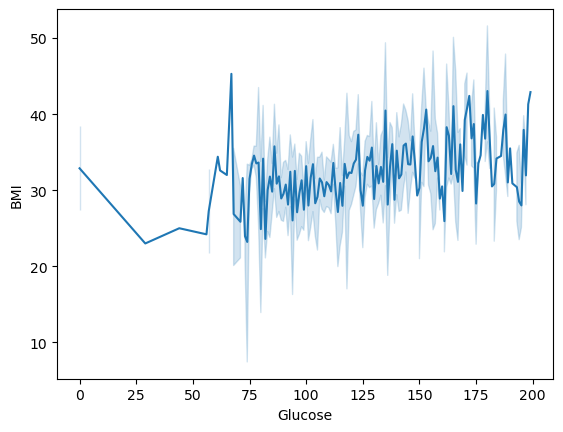

In [27]:
# Line plot for a variable (Glucose) & (BMI)
sns.lineplot(data=dfmedian, x='Glucose', y='BMI')
plt.show()

This line plot shows the relationship between Glucose levels and BMI. The fluctuations in the line indicate high variability in BMI values across different glucose levels. There is no clear trend, suggesting a weak or inconsistent relationship between the two variables.

**Scatter Plot**

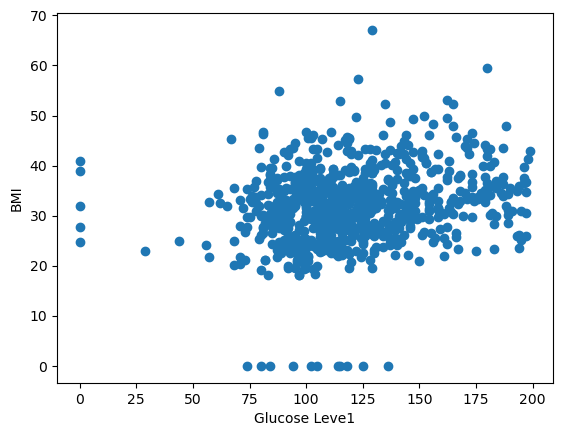

In [28]:
#Scatter Plot for Glucose and BMI
plt.scatter(dfmedian['Glucose'], dfmedian['BMI'])
plt.xlabel('Glucose Leve1')
plt.ylabel('BMI')
plt.show()

This scatter plot shows the relationship between Glucose levels and BMI. The data points are widely spread, indicating no strong correlation between the two variables. Most values are clustered in the middle range, suggesting that BMI does not have a clear impact on glucose levels.

**Box plot**

/opt/conda/envs/anaconda-panel-2023.05-py310/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


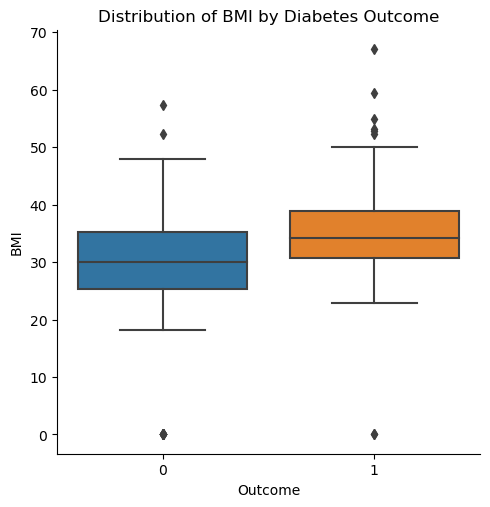

In [29]:
# Plotting a bar chart for a categorical column using catplot
sns.catplot(x="Outcome", y="BMI", kind="box", data=dfmedian)
plt.title("Distribution of BMI by Diabetes Outcome")
plt.show()

This box plot shows the average BMI for diabetic and non-diabetic patients.  
It helps compare the overall BMI level between the two groups.  
From the plot, we can observe whether patients with diabetes tend to have higher average BMI than those without diabetes.

**scatter plot with regression line**

Correlation coefficient =  0.22


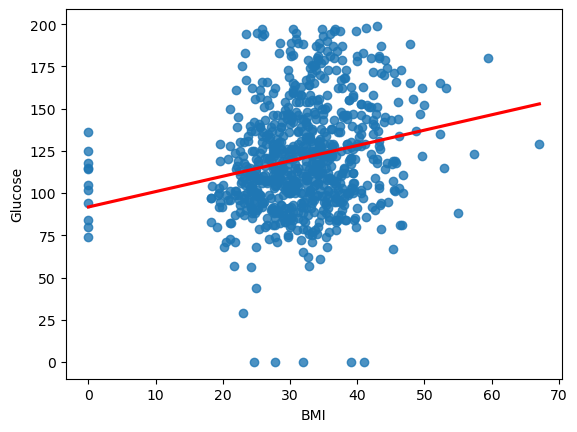

In [30]:
# Plotting a scatter plot with a regression line
sns.regplot(x= dfmedian["BMI"], y= dfmedian["Glucose"], ci=None, line_kws={"color": "red"})
print('Correlation coefficient = ', np.corrcoef(dfmedian["BMI"], dfmedian["Glucose"])[0, 1].round(2))

This code analyzes the relationship between Body Mass Index (BMI) and Glucose Level using a Regression Plot, and it also calculates the Correlation Coefficient between the two variables.

**--3D--**

**Scatterplot**

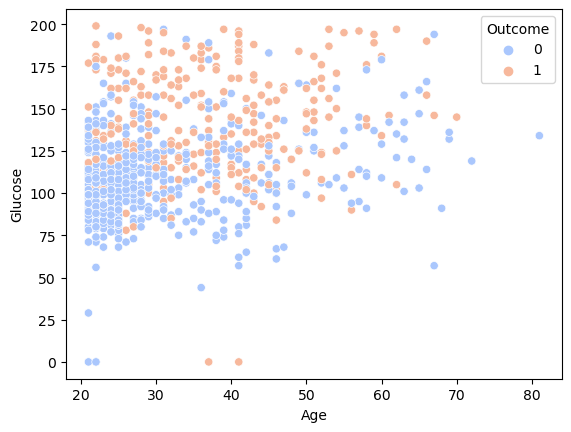

In [31]:
#Scatter Plot for Glucose, Age, and Outcome
sns.scatterplot(data = dfmedian, x = 'Age', y = 'Glucose', hue = 'Outcome', palette = 'coolwarm')
plt.show()

This scatter plot shows the relationship between Age and Glucose levels, colored by Outcome.  
It helps to visualize how glucose values differ between diabetic and non-diabetic patients across different age groups.  
We can observe that diabetic patients generally have higher glucose levels.

**Heatmap**

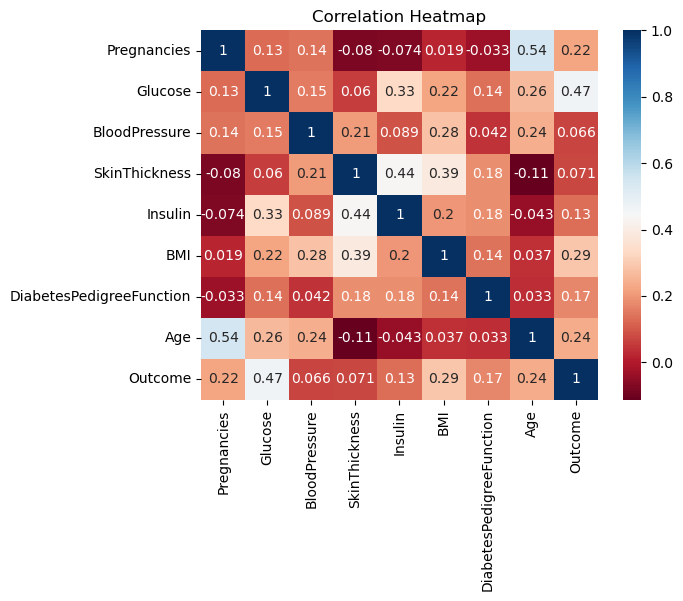

In [32]:
#plot the heatmap
corrHeatMap = dfmedian.corr().round(3)
sns.heatmap(corrHeatMap, cmap='RdBu', annot=True)
plt.title("Correlation Heatmap")
plt.show()

This heatmap shows the correlation between the numerical features in the dataset.  
Darker colors represent stronger positive or negative relationships.  
For example, Glucose and Outcome have a strong positive correlation, meaning higher glucose levels are often associated with diabetes.

**Pairplot**

In [ ]:
sns.pairplot (dfmedian)
plt.show()

This pairplot shows the relationships between multiple features in the dataset.  
It displays scatter plots for each pair of features and histograms for individual ones.  
The colors represent the diabetes outcome, making it easier to compare patterns between diabetic and non-diabetic patients.

# **End of phase 1**

# **Thank you !!**

__________________________________________________________________________________________

# **Phase 2**

# **Machine Learning**

In [37]:
# Import train & test split to split the data into training and test sets
from sklearn.model_selection import train_test_split

# Import classifiers/models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier

# Import model evaluation metrics
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix

In [38]:
# Checking the head
dfmedian.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72,35,0,33.6,0.627,50.0,1
1,1,85.0,66,29,0,26.6,0.351,31.0,0
2,8,183.0,64,0,0,23.3,0.672,32.0,1
3,1,89.0,66,23,94,28.1,0.167,21.0,0
4,0,137.0,40,35,168,43.1,2.288,33.0,1


In [39]:
print(dfmedian.isnull().any())

Pregnancies                 False
Glucose                     False
BloodPressure               False
SkinThickness               False
Insulin                     False
BMI                         False
DiabetesPedigreeFunction    False
Age                         False
Outcome                     False
dtype: bool


In [40]:
# Checking the number of rows and columns
dfmedian.shape

(766, 9)

In [41]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(dfmedian.drop(labels='Outcome', axis=1), 
                                                    dfmedian['Outcome'], test_size=0.30, 
                                                    random_state=101)

# **1- Logistic Regression**

In [42]:
# Fit LR model with training data
lr = LogisticRegression()
lr.fit(X_train, y_train)

/opt/conda/envs/anaconda-panel-2023.05-py310/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [43]:
# Make predictions for test data
lr_pred = lr.predict(X_test)

In [44]:
# Compute confusion matrix
cm = confusion_matrix(y_test,lr_pred)
print(cm)

[[116  23]
 [ 45  46]]


In [45]:
# Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, lr_pred)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 70.43%


In [46]:
cr = classification_report(y_test, lr_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.72      0.83      0.77       139
           1       0.67      0.51      0.58        91

    accuracy                           0.70       230
   macro avg       0.69      0.67      0.67       230
weighted avg       0.70      0.70      0.69       230



# **2- KNN** 

In [47]:
#Fit KNN model with training data
knn = KNeighborsClassifier(n_neighbors=4)
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=4)

In [48]:
#Make predictions for test data
knn_pred = knn.predict(X_test)

In [49]:
#Compute confusion matrix
cm = confusion_matrix(y_test,knn_pred)
print(cm)

[[117  22]
 [ 52  39]]


In [50]:
#Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, knn_pred)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 67.83%


In [51]:
# Print the classification report
cr = classification_report(y_test, knn_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.69      0.84      0.76       139
           1       0.64      0.43      0.51        91

    accuracy                           0.68       230
   macro avg       0.67      0.64      0.64       230
weighted avg       0.67      0.68      0.66       230



# **3- Decision Trees** 

In [52]:
dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

DecisionTreeClassifier()

In [53]:
# Make predictions for test data
dt_pred = dt.predict(X_test)

In [54]:
# Compute confusion matrix
cm = confusion_matrix(y_test,dt_pred)
print(cm)

[[106  33]
 [ 34  57]]


In [55]:
# Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, dt_pred)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 70.87%


In [56]:
cr = classification_report(y_test, dt_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.76      0.76      0.76       139
           1       0.63      0.63      0.63        91

    accuracy                           0.71       230
   macro avg       0.70      0.69      0.69       230
weighted avg       0.71      0.71      0.71       230



## **4- Naive Bayes** 

In [57]:
# Fit model with training data
GNB = GaussianNB()
GNB.fit(X_train, y_train)

GaussianNB()

In [58]:
# Make predictions for test data
NB_pred = GNB.predict(X_test)

In [59]:
# Compute confusion matrix
NB = confusion_matrix(y_test,NB_pred)
print(NB)

[[109  30]
 [ 39  52]]


In [60]:
# Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, NB_pred)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 70.00%


In [61]:
cr = classification_report(y_test, NB_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.74      0.78      0.76       139
           1       0.63      0.57      0.60        91

    accuracy                           0.70       230
   macro avg       0.69      0.68      0.68       230
weighted avg       0.70      0.70      0.70       230



## **5- Support Vector Machine** 

In [62]:
# SVM needs features to be scaled
#Creating SVM model
SVC = svm.SVC()

#Fitting the model
SVC.fit(X_train, y_train)

SVC()

In [63]:
#Predicting on test set
predSVC = SVC.predict(X_test)

In [64]:
# Compute confusion matrix
sv = confusion_matrix(y_test,predSVC)
print(sv)

[[121  18]
 [ 47  44]]


In [65]:
# Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, predSVC)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 71.74%


In [66]:
cr = classification_report(y_test, predSVC)
print(cr)

              precision    recall  f1-score   support

           0       0.72      0.87      0.79       139
           1       0.71      0.48      0.58        91

    accuracy                           0.72       230
   macro avg       0.71      0.68      0.68       230
weighted avg       0.72      0.72      0.70       230



## **6- Random Forest** 

In [67]:
#Making an object for RFC
RF = RandomForestClassifier(n_estimators=100, random_state=0)

#Fitting the model
RF.fit(X_train, y_train)

#Predicting on test set
pred = RF.predict(X_test)

In [68]:
# compute Confusiob matrix
print(confusion_matrix(y_test,pred))

[[118  21]
 [ 46  45]]


In [69]:
# Evaluate model performance (accuracy)
accuracy = accuracy_score(y_test, pred)
print("Accuracy: %.2f%%" % (accuracy * 100.0))

Accuracy: 70.87%


In [70]:
cr = classification_report(y_test, pred)
print(cr)

              precision    recall  f1-score   support

           0       0.72      0.85      0.78       139
           1       0.68      0.49      0.57        91

    accuracy                           0.71       230
   macro avg       0.70      0.67      0.68       230
weighted avg       0.70      0.71      0.70       230



# **Which model is the best for diabetes prediction ?**

Given the importance of precision in medical datasets such as those related to diabetes, accuracy was selected as the primary metric for model evaluation. Among all the models tested, Support Vector Machine(SVM) outperformed the others with an accuracy score of 71.74%

# **Conclusion**

1- We used different plots (line, scatter, boxplot,heatmap, etc.) to explore relationships in the dataset.
“Most individuals in the dataset are non-diabetic. (Glucose) shows the strongest relationship withdiabetes, followed by a weaker link with(BMI)”.

2- During preprocessing, we cleaned the dataand handled missing values by replacing themwith the (median), which was the most suitablemethod for our dataset.

3- Six classification models were tested(Logistic Regression - KNN - Decision Tree - Naive Bayes - SVM - Random Forest)
“SVM achieved the highest accuracy (71.74%) and was the best fit for our data, providing the best results and effectively supporting early diabetes prediction, whereas KNN performed the worst with an accuracy of only (67.83%)”.

# **End of our project**
# **Thank you !!**